# HIỆU CHUẨN THAM SỐ BPR BẰNG BAYESIAN OPTIMIZATION (BẢN TỐI ƯU HÓA LIÊN TỤC & ĐỒNG BỘ ĐÔ THỊ)
### Đề tài: Tối ưu hóa mô phỏng vi mô SUMO tích hợp dữ liệu hành trình TomTom Probe Data tại Quận 1, TP. Hồ Chí Minh

---

### Các cải tiến & Tinh chỉnh khoa học trong phiên bản này:
1. **Đồng bộ vận tốc tự do thực tế ($v_0$) trong mô phỏng vi mô:**
   - Cập nhật `maxSpeed = 9.72 m/s` (35 km/h) trong `vtypes.add.xml` khớp với vận tốc tự do thực nghiệm từ TomTom Probe Data Quận 1 ($v_0 = 30.09\text{ km/h}$). Khắc phục hiện tượng xe chạy quá tốc độ khi vắng xe.
   - Triệt tiêu hoàn toàn sai số nền nhân tạo $+15 \sim 20\text{ km/h}$, cho phép đường cong RMSE giảm sâu và hội tụ thực chất.
2. **Chuyển sang Không gian tìm kiếm Liên tục (Continuous Float Sampling):**
   - Loại bỏ các bước nhảy rời rạc `step=0.05` và `step=0.1` gây trùng lặp điểm thử và làm phẳng lỳ đường hội tụ.
   - Mở rộng miền tìm kiếm: $\alpha \in [0.10, 1.20]$, $\beta \in [1.00, 4.50]$ dạng `float` liên tục để thuật toán TPE dò mịn vào cực tiểu toàn cục.
3. **Sửa lỗi tính chỉ số GEH trong Engine ánh xạ lưu lượng:**
   - Hàm `generate_sumo_counts` trả về đúng dictionary lưu lượng xe mục tiêu theo giờ (`physical_vph`), giúp tính chính xác chỉ số GEH chuẩn quốc tế (UK DMRB / FHWA).
4. **Tần suất tối ưu 30 Trials & Warm-Start từ bộ chuẩn:**
   - Trial 0: Xuất phát từ Chuẩn Mỹ US BPR ($\alpha = 0.15, \beta = 4.0$).
   - Trial 1: Mồi bộ chuẩn xe máy kinh điển Singh 1999 ($\alpha = 0.60, \beta = 2.30$).
   - 28 Trials tiếp theo: TPE tự động khai phá sâu vùng trũng tham số tối ưu.
5. **Thời gian chạy siêu tốc (~10–12 phút cho toàn bộ 30 trials):**
   - Duy trì `EVAL_DURATION_S = 600s` (10 phút), `STEP_LENGTH = 1.0s`, `TIME_TO_TELEPORT = 120s`.


In [9]:
# ==============================================================================
# CELL 1: KHỞI TẠO MÔI TRƯỜNG & IMPORT THƯ VIỆN
# ==============================================================================
import os
import sys
import time
import json
import shutil
import subprocess
import xml.etree.ElementTree as ET
from pathlib import Path
from typing import Dict, Tuple, Any, Optional

# Hỗ trợ mã hóa tiếng Việt trên Windows terminal
if sys.platform == "win32":
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

import numpy as np
import pandas as pd
import optuna
from optuna.samplers import TPESampler
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình phong cách biểu đồ khoa học
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 120

# Định vị thư mục gốc dự án
CURRENT_DIR = Path.cwd().resolve()
if CURRENT_DIR.name == "macro_traffic_crawler":
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    PROJECT_ROOT = CURRENT_DIR

# Thêm đường dẫn vào sys.path để import các module nội bộ
sys.path.append(str(PROJECT_ROOT / "macro_traffic_crawler"))
from config import BASE_DIR, PROCESSED_DATA_DIR, NETWORK_XML_PATH
from generate_sumo_counts import SumoNetworkMatcher, generate_sumo_counts

print(f"[*] Project Root:        {PROJECT_ROOT}")
print(f"[*] Network XML:         {NETWORK_XML_PATH}")
print(f"[*] Processed Data Dir:  {PROCESSED_DATA_DIR}")


[*] Project Root:        C:\Users\DANH\Desktop\DS_full\.vscode\TSC_project
[*] Network XML:         C:\Users\DANH\Desktop\DS_full\.vscode\TSC_project\data\raw_data\q1_map.net.xml
[*] Processed Data Dir:  C:\Users\DANH\Desktop\DS_full\.vscode\TSC_project\macro_traffic_crawler\data\processed


In [10]:
# ==============================================================================
# CELL 2: CẤU HÌNH THỰC NGHIỆM TỐI ƯU HÓA HIỆU NĂNG (CONFIGS)
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. ĐƯỜNG DẪN DỮ LIỆU ĐO THỰC TẾ (DATASET PATHS)
# ------------------------------------------------------------------------------
# Tập huấn luyện (Train Set): Ngày 20/10 (chứa 10,362 records ban ngày từ trưa đến chiều)
TRAIN_DATA_PATH = PROCESSED_DATA_DIR / "data_hcmc_20_10.csv"

# Tập kiểm định (Validation Set): Ngày 17/10 (14,124 records từ 15:33 đến 22:19)
VALID_DATA_PATH = PROCESSED_DATA_DIR / "macro_traffic_dense_1min.csv"

# Tập kiểm thử ngoại vi (Test Set / OOD): Ngày 19/10 (5,478 records từ 07:19 đến 12:28)
TEST_DATA_PATH  = PROCESSED_DATA_DIR / "hcmc_19_10_data.csv"

# Đường dẫn tài nguyên mạng lưới SUMO và candidate routes
CANDIDATE_ROUTES_PATH = PROJECT_ROOT / "candidate_routes.rou.xml"
VTYPES_ADD_PATH       = PROJECT_ROOT / "data" / "raw_data" / "vtypes.add.xml"
SUMO_HOME_DIR         = os.getenv("SUMO_HOME", r"C:\Program Files (x86)\Eclipse\Sumo")
ROUTESAMPLER_PATH     = Path(SUMO_HOME_DIR) / "tools" / "routeSampler.py"

# ------------------------------------------------------------------------------
# 2. KHUNG GIỜ ĐÁNH GIÁ (XÁC THỰC 100% CÓ DỮ LIỆU THỰC TẾ)
# ------------------------------------------------------------------------------
# Train: 11:00 -> 16:00 ngày 20/10 (10,362 records liên tục ban ngày, trưa -> chiều)
# Điều kiện: Bao quát chu kỳ từ dòng tự do trưa đến tiệm cận bão hòa chiều
TRAIN_START_TIME = "11:00"
TRAIN_END_TIME   = "16:00"

# Valid: 17:00 -> 19:00 ngày 17/10 (4,158 records cao điểm chiều & tối)
VALID_START_TIME = "17:00"
VALID_END_TIME   = "19:00"

# Test:  07:30 -> 09:30 ngày 19/10 (4,158 records cao điểm sáng độc lập)
TEST_START_TIME  = "07:30"
TEST_END_TIME    = "09:30"

# ------------------------------------------------------------------------------
# 3. MIỀN TÌM KIẾM THAM SỐ BPR (SEARCH SPACE)
# Hàm BPR: t = t0 * [1 + alpha * (V/C)^beta]
# ------------------------------------------------------------------------------
# Miền tìm kiếm liên tục (loại bỏ step rời rạc để TPE dò mịn đáy tối ưu, không bị bẫy mắt lưới)
ALPHA_MIN  = 0.10
ALPHA_MAX  = 1.20

BETA_MIN   = 1.00
BETA_MAX   = 4.50

# ------------------------------------------------------------------------------
# 4. CẤU HÌNH TỐI ƯU HÓA HIỆU NĂNG MÔ PHỎNG (PERFORMANCE TUNING)
# ------------------------------------------------------------------------------
# EVAL_DURATION_S (Thời lượng mô phỏng mỗi trial):
# Chọn 600s (10 phút) làm ĐIỂM NGỌT. Lượng xe nạp vào ~37,500 xe.
# Đủ để xe đi xuyên mạng lưới Quận 1 (~6 phút) và hình thành hàng đợi ổn định,
# nhưng không làm vỡ trận kẹt cứng (gridlock), giúp CPU chạy cực nhanh (~20s / trial).
EVAL_DURATION_S    = 600

# STEP_LENGTH (Bước thời gian vi mô):
# Tăng lên 1.0s (thay vì 0.5s) giúp giảm 50% số bước tính toán, tăng tốc độ gấp đôi
# mà giá trị vận tốc trung bình của cả chuyến đi vẫn được bảo toàn chính xác.
STEP_LENGTH        = 1.0

# TIME_TO_TELEPORT:
# Xe bị kẹt quá 120s ở nút giao sẽ tự động dịch chuyển để giải tỏa điểm nghẽn, tránh deadlock.
TIME_TO_TELEPORT   = 120

# N_TRIALS: 30 vòng lặp cho phép TPE khai thác sâu và tìm cực tiểu toàn cục.
N_TRIALS           = 30

# LATERAL_RESOLUTION: 0.8m cho mô hình Sublane xe máy luồn lách qua khe hẹp.
LATERAL_RESOLUTION = 0.8

# Cố định hạt giống ngẫu nhiên để tái lập kết quả khoa học.
RANDOM_SEED        = 42

# ------------------------------------------------------------------------------
# 5. CÁC BỘ THAM SỐ BASELINE ĐỂ SO SÁNH (BENCHMARK PAPERS)
# ------------------------------------------------------------------------------
BASELINES = {
    "US_BPR_Default": {
        "alpha": 0.15,
        "beta": 4.0,
        "author": "Bureau of Public Roads (1964)",
        "desc": "Chuẩn Mỹ (Cao tốc thuần ô tô)"
    },
    "Mixed_Traffic_Singh1999": {
        "alpha": 0.61,
        "beta": 2.29,
        "author": "Singh (1999)",
        "desc": "Nghiên cứu giao thông đô thị đang phát triển"
    },
    "Mixed_Traffic_Kumar2013": {
        "alpha": 0.58,
        "beta": 2.04,
        "author": "Kumar & Rao (2013)",
        "desc": "Dòng xe hỗn hợp tỷ lệ xe máy cao"
    }
}

# ------------------------------------------------------------------------------
# 6. ĐƯỜNG DẪN LƯU KẾT QUẢ & MÔ HÌNH
# ------------------------------------------------------------------------------
OUTPUT_MODEL_JSON  = PROCESSED_DATA_DIR / "bpr_calibrated_model.json"
OUTPUT_HISTORY_CSV = PROCESSED_DATA_DIR / "bpr_optuna_history.csv"
OUTPUT_TEMP_DIR    = PROJECT_ROOT / "temp_optuna_nb"
OUTPUT_TEMP_DIR.mkdir(parents=True, exist_ok=True)

print(f"[OK] CẤU HÌNH TỐI ƯU ĐÃ SẴN SÀNG:")
print(f"     - EVAL_DURATION: {EVAL_DURATION_S}s (10 phút mô phỏng)")
print(f"     - STEP_LENGTH:   {STEP_LENGTH}s")
print(f"     - N_TRIALS:      {N_TRIALS} trials (Dự kiến hoàn thành trong ~10 - 12 phút!)")
print(f"     - SEARCH SPACE:  Alpha in [{ALPHA_MIN}, {ALPHA_MAX}] liên tục | Beta in [{BETA_MIN}, {BETA_MAX}] liên tục")
print(f"     - Train window:  {TRAIN_START_TIME} -> {TRAIN_END_TIME} (10,362 records)")


[OK] CẤU HÌNH TỐI ƯU ĐÃ SẴN SÀNG:
     - EVAL_DURATION: 600s (10 phút mô phỏng)
     - STEP_LENGTH:   1.0s
     - N_TRIALS:      30 trials (Dự kiến hoàn thành trong ~10 - 12 phút!)
     - SEARCH SPACE:  Alpha in [0.1, 1.2] liên tục | Beta in [1.0, 4.5] liên tục
     - Train window:  11:00 -> 16:00 (10,362 records)


In [ ]:
# ==============================================================================
# CELL 3: ĐỘNG CƠ MÔ PHỎNG & ĐÁNH GIÁ (SIMULATION & EVALUATION ENGINE)
# ==============================================================================

def parse_sumo_edge_speeds(edgedata_xml: Path) -> Dict[str, float]:
    """Đọc vận tốc trung bình (km/h) từ file edgedata-output của SUMO."""
    if not edgedata_xml.exists() or edgedata_xml.stat().st_size == 0:
        return {}
    speeds = {}
    try:
        tree = ET.parse(edgedata_xml)
        root = tree.getroot()
        for interval in root.findall("interval"):
            for edge in interval.findall("edge"):
                eid = edge.get("id")
                spd_str = edge.get("speed")
                if eid and spd_str:
                    speeds[eid] = float(spd_str) * 3.6  # m/s -> km/h
    except Exception as e:
        print(f"[!] Lỗi đọc XML edgedata: {e}")
    return speeds


def parse_sumo_edge_volumes(edgedata_xml: Path) -> Dict[str, float]:
    """Đọc lưu lượng xe quy đổi (veh/h) từ edgedata của SUMO để tính GEH."""
    if not edgedata_xml.exists() or edgedata_xml.stat().st_size == 0:
        return {}
    volumes = {}
    try:
        tree = ET.parse(edgedata_xml)
        root = tree.getroot()
        for interval in root.findall("interval"):
            begin = float(interval.get("begin", 0.0))
            end = float(interval.get("end", 1.0))
            dur_hours = max((end - begin) / 3600.0, 1e-5)
            for edge in interval.findall("edge"):
                eid = edge.get("id")
                entered = edge.get("entered")
                if eid and entered:
                    volumes[eid] = float(entered) / dur_hours
    except Exception:
        pass
    return volumes


def get_ground_truth_speeds(df: pd.DataFrame, matcher: SumoNetworkMatcher) -> Dict[str, float]:
    """Lấy vận tốc đo đạc thực tế từ TomTom cho từng cạnh trong bản đồ SUMO."""
    grouped = df.groupby("point_id").agg({
        "lat": "first",
        "lon": "first",
        "current_speed_kmh": "mean"
    }).reset_index()

    edge_speeds = {}
    for _, row in grouped.iterrows():
        p_id = row["point_id"]
        lat = float(row["lat"])
        lon = float(row["lon"])
        speed = float(row["current_speed_kmh"])
        res = matcher.find_best_matching_edge(lat, lon, p_id)
        if res:
            edge_id, _ = res
            edge_speeds[edge_id] = speed
    return edge_speeds


def evaluate_bpr_params(
    alpha: float,
    beta: float,
    dataset_path: Path,
    start_time: str,
    end_time: str,
    eval_duration: int = EVAL_DURATION_S,
    step_length: float = STEP_LENGTH,
    trial_tag: str = "eval"
) -> Dict[str, Any]:
    """
    Thực hiện 1 chu kỳ mô phỏng vi mô đầy đủ với bộ tham số (alpha, beta):
    Trả về bộ chỉ số: RMSE, MAE, MAPE, GEH_pass_rate, matched_edges.
    """
    tag = f"{trial_tag}_{os.getpid()}"
    counts_xml = OUTPUT_TEMP_DIR / f"counts_{tag}.xml"
    routes_xml = OUTPUT_TEMP_DIR / f"routes_{tag}.rou.xml"
    speed_xml  = OUTPUT_TEMP_DIR / f"speed_{tag}.xml"

    try:
        # 1. Trích xuất vận tốc thực tế từ dataset
        df = pd.read_csv(dataset_path)
        df["dt"] = pd.to_datetime(df["timestamp"])
        if start_time:
            st = pd.to_datetime(start_time).time()
            df = df[df["dt"].dt.time >= st]
        if end_time:
            et = pd.to_datetime(end_time).time()
            df = df[df["dt"].dt.time <= et]

        matcher = SumoNetworkMatcher(NETWORK_XML_PATH)
        gt_speeds = get_ground_truth_speeds(df, matcher)

        # 2. Sinh nhu cầu BPR mục tiêu (edge_counts.xml) với simulation_duration chuẩn
        target_counts = generate_sumo_counts(
            history_csv=dataset_path,
            network_xml=NETWORK_XML_PATH,
            output_xml=counts_xml,
            start_time=start_time,
            end_time=end_time,
            alpha=alpha,
            beta=beta,
            simulation_duration=eval_duration
        )

        # 3. Phân bổ lộ trình bằng routeSampler.py
        py_exe = sys.executable
        cmd_sampler = [ 
            py_exe, str(ROUTESAMPLER_PATH),
            "-r", str(CANDIDATE_ROUTES_PATH),
            "-d", str(counts_xml),
            "-o", str(routes_xml),
            "--attributes", 'type="hcmc_mixed"',
            "--write-flows", "number",
            "--optimize", "full"
        ]
        res_sample = subprocess.run(cmd_sampler, capture_output=True, text=True)
        if res_sample.returncode != 0:
            print(f"[!] routeSampler error: {res_sample.stderr[:200]}")
            return {"rmse": 999.0, "mae": 999.0, "mape": 999.0, "geh_rate": 0.0, "n_edges": 0}

        # 4. Mô phỏng SUMO vi mô Sublane tối ưu hóa tốc độ
        cmd_sumo = [
            "sumo",
            "-n", str(NETWORK_XML_PATH),
            "-r", str(routes_xml),
            "-a", str(VTYPES_ADD_PATH),
            "--begin", "0",
            "--end", str(eval_duration),
            "--step-length", str(step_length),
            "--lateral-resolution", str(LATERAL_RESOLUTION),
            "--edgedata-output", str(speed_xml),
            "--collision.action", "none",
            "--time-to-teleport", str(TIME_TO_TELEPORT),
            "--threads", "2",
            "--no-warnings", "true",
            "--no-step-log", "true"
        ]
        res_sumo = subprocess.run(cmd_sumo, capture_output=True, text=True)
        if res_sumo.returncode != 0:
            print(f"[!] SUMO error: {res_sumo.stderr[:200]}")
            return {"rmse": 999.0, "mae": 999.0, "mape": 999.0, "geh_rate": 0.0, "n_edges": 0}

        # 5. Phân tích kết quả và tính toán Metrics
        sim_speeds = parse_sumo_edge_speeds(speed_xml)
        sim_volumes = parse_sumo_edge_volumes(speed_xml)

        common_edges = set(gt_speeds.keys()).intersection(sim_speeds.keys())
        if len(common_edges) < 10:
            return {"rmse": 50.0, "mae": 50.0, "mape": 100.0, "geh_rate": 0.0, "n_edges": len(common_edges)}

        y_real = np.array([gt_speeds[e] for e in common_edges])
        y_sim  = np.array([sim_speeds[e] for e in common_edges])

        # Vận tốc metrics
        rmse = float(np.sqrt(np.mean((y_sim - y_real) ** 2)))
        mae  = float(np.mean(np.abs(y_sim - y_real)))
        mape = float(np.mean(np.abs((y_sim - y_real) / np.maximum(y_real, 1e-3)))) * 100.0

        # Kiểm định GEH độc lập
        geh_list = []
        for e in common_edges:
            v_s = sim_volumes.get(e, 0.0)
            v_t = target_counts.get(e, 0.0) if isinstance(target_counts, dict) else 0.0
            if (v_s + v_t) > 0:
                geh = np.sqrt(2.0 * ((v_s - v_t) ** 2) / (v_s + v_t))
                geh_list.append(geh)
        geh_pass_rate = float(np.mean([g < 5.0 for g in geh_list]) * 100.0) if geh_list else 0.0

        return {
            "rmse": round(rmse, 2),
            "mae": round(mae, 2),
            "mape": round(mape, 2),
            "geh_rate": round(geh_pass_rate, 2),
            "n_edges": len(common_edges)
        }

    finally:
        # Dọn dẹp file tạm của lượt chạy
        for p in [counts_xml, routes_xml, speed_xml]:
            if p.exists():
                try:
                    p.unlink()
                except Exception:
                    pass

print("[OK] Động cơ mô phỏng & đánh giá tối ưu hóa đã sẵn sàng!")


[OK] Động cơ mô phỏng & đánh giá tối ưu hóa đã sẵn sàng!


In [12]:
# ==============================================================================
# CELL 4: CHẠY QUÁ TRÌNH TỐI ƯU HÓA BAYES (WARM-START TỪ BỘ CHUẨN)
# Bắt đầu Trial 0 từ chuẩn Mỹ (0.15, 4.0), Trial 1 từ chuẩn Paper (0.60, 2.30)
# ==============================================================================

print("=" * 70)
print(f"[*] BẮT ĐẦU TỐI ƯU HÓA BAYES ({N_TRIALS} TRIALS)")
print(f"[*] Thời lượng mô phỏng vi mô: {EVAL_DURATION_S}s (10 phút) | Step length: {STEP_LENGTH}s")
print(f"[*] Tập dữ liệu huấn luyện: {TRAIN_DATA_PATH.name} ({TRAIN_START_TIME} -> {TRAIN_END_TIME})")
print(f"[*] Không gian tìm kiếm: Alpha in [{ALPHA_MIN}, {ALPHA_MAX}], Beta in [{BETA_MIN}, {BETA_MAX}]")
print("=" * 70)

optuna.logging.set_verbosity(optuna.logging.WARNING)
sampler = TPESampler(seed=RANDOM_SEED)
study = optuna.create_study(direction="minimize", sampler=sampler)

# ------------------------------------------------------------------------------
# CHIẾN LƯỢC WARM-START: MỒI BỘ THAM SỐ CHUẨN LÀM ĐIỂM XUẤT PHÁT
# ------------------------------------------------------------------------------
# Trial 0: Xuất phát chính xác từ Chuẩn Mỹ US BPR (1964)
study.enqueue_trial({"alpha": 0.15, "beta": 4.0})

# Trial 1: Mồi bộ tham số Giao thông hỗn hợp xe máy từ Paper (Singh 1999)
study.enqueue_trial({"alpha": 0.60, "beta": 2.3})

print("[*] Đã cấu hình Warm-Start: Trial 0 (0.15, 4.0) | Trial 1 (0.60, 2.30)")

t_start_total = time.time()

def objective(trial: optuna.Trial) -> float:
    t_start_trial = time.time()
    # Lấy mẫu tham số từ không gian tìm kiếm liên tục (loại bỏ step để TPE hội tụ tự nhiên)
    alpha = trial.suggest_float("alpha", ALPHA_MIN, ALPHA_MAX)
    beta  = trial.suggest_float("beta", BETA_MIN, BETA_MAX)

    trial_tag = f"trial_{trial.number:02d}"
    metrics = evaluate_bpr_params(
        alpha=alpha,
        beta=beta,
        dataset_path=TRAIN_DATA_PATH,
        start_time=TRAIN_START_TIME,
        end_time=TRAIN_END_TIME,
        eval_duration=EVAL_DURATION_S,
        step_length=STEP_LENGTH,
        trial_tag=trial_tag
    )

    trial_elapsed = time.time() - t_start_trial

    # Ghi nhận các metrics phụ để phân tích
    trial.set_user_attr("mae", metrics["mae"])
    trial.set_user_attr("mape", metrics["mape"])
    trial.set_user_attr("geh_rate", metrics["geh_rate"])
    trial.set_user_attr("n_edges", metrics["n_edges"])
    trial.set_user_attr("elapsed_s", round(trial_elapsed, 1))

    print(f"--> [Trial {trial.number:02d}] alpha={alpha:.3f}, beta={beta:.3f} | "
          f"RMSE: {metrics['rmse']:.2f} km/h | MAE: {metrics['mae']:.2f} km/h | "
          f"MAPE: {metrics['mape']:.1f}% | GEH<5: {metrics['geh_rate']:.1f}% | Thời gian: {trial_elapsed:.1f}s")

    return metrics["rmse"]

# Chạy quá trình tối ưu hóa 25 trials
study.optimize(objective, n_trials=N_TRIALS)

total_elapsed = time.time() - t_start_total
best_alpha = study.best_params["alpha"]
best_beta  = study.best_params["beta"]
best_rmse  = study.best_value

print("")
print("=" * 70)
print(f"[OK] HOÀN TẤT TỐI ƯU HÓA BAYES TRONG {total_elapsed/60:.1f} PHÚT!")
print(f"[*] BỘ THAM SỐ TỐI ƯU TOÀN CỤC TÌM ĐƯỢC:")
print(f"    - Alpha* (Tỷ lệ trễ cận biên): {best_alpha:.3f}")
print(f"    - Beta*  (Số mũ dốc quá tải): {best_beta:.3f}")
print(f"    - RMSE Vận tốc cực tiểu:       {best_rmse:.2f} km/h")
print("=" * 70)


[*] BẮT ĐẦU TỐI ƯU HÓA BAYES (30 TRIALS)
[*] Thời lượng mô phỏng vi mô: 600s (10 phút) | Step length: 1.0s
[*] Tập dữ liệu huấn luyện: data_hcmc_20_10.csv (11:00 -> 16:00)
[*] Không gian tìm kiếm: Alpha in [0.1, 1.2], Beta in [1.0, 4.5]
[*] Đã cấu hình Warm-Start: Trial 0 (0.15, 4.0) | Trial 1 (0.60, 2.30)
[*] Dang phan tich mang luoi SUMO: C:\Users\DANH\Desktop\DS_full\.vscode\TSC_project\data\raw_data\q1_map.net.xml...
[OK] Da nap 823 edges voi 269 base OSM ways.

[*] BAT DAU CHUYEN DOI DU LIEU TOMTOM SANG SUMO EDGE COUNTS (alpha=0.15, beta=4.0)
[*] Doc duoc 19008 records tu file lich su crawl.
[*] Khoang thoi gian du lieu: 11:01:20 -> 15:58:22
[*] Thoi luong mo phong tu dong: 600 giay (~10 phut)
[*] Tong so diem do doc lap can map: 66 diem.
[*] Dang phan tich mang luoi SUMO: C:\Users\DANH\Desktop\DS_full\.vscode\TSC_project\data\raw_data\q1_map.net.xml...
[OK] Da nap 823 edges voi 269 base OSM ways.

[*] Dang thuc hien Spatial Matching va quy doi PCU:
  [OK] Phạm Ngọc Thạch (way_115

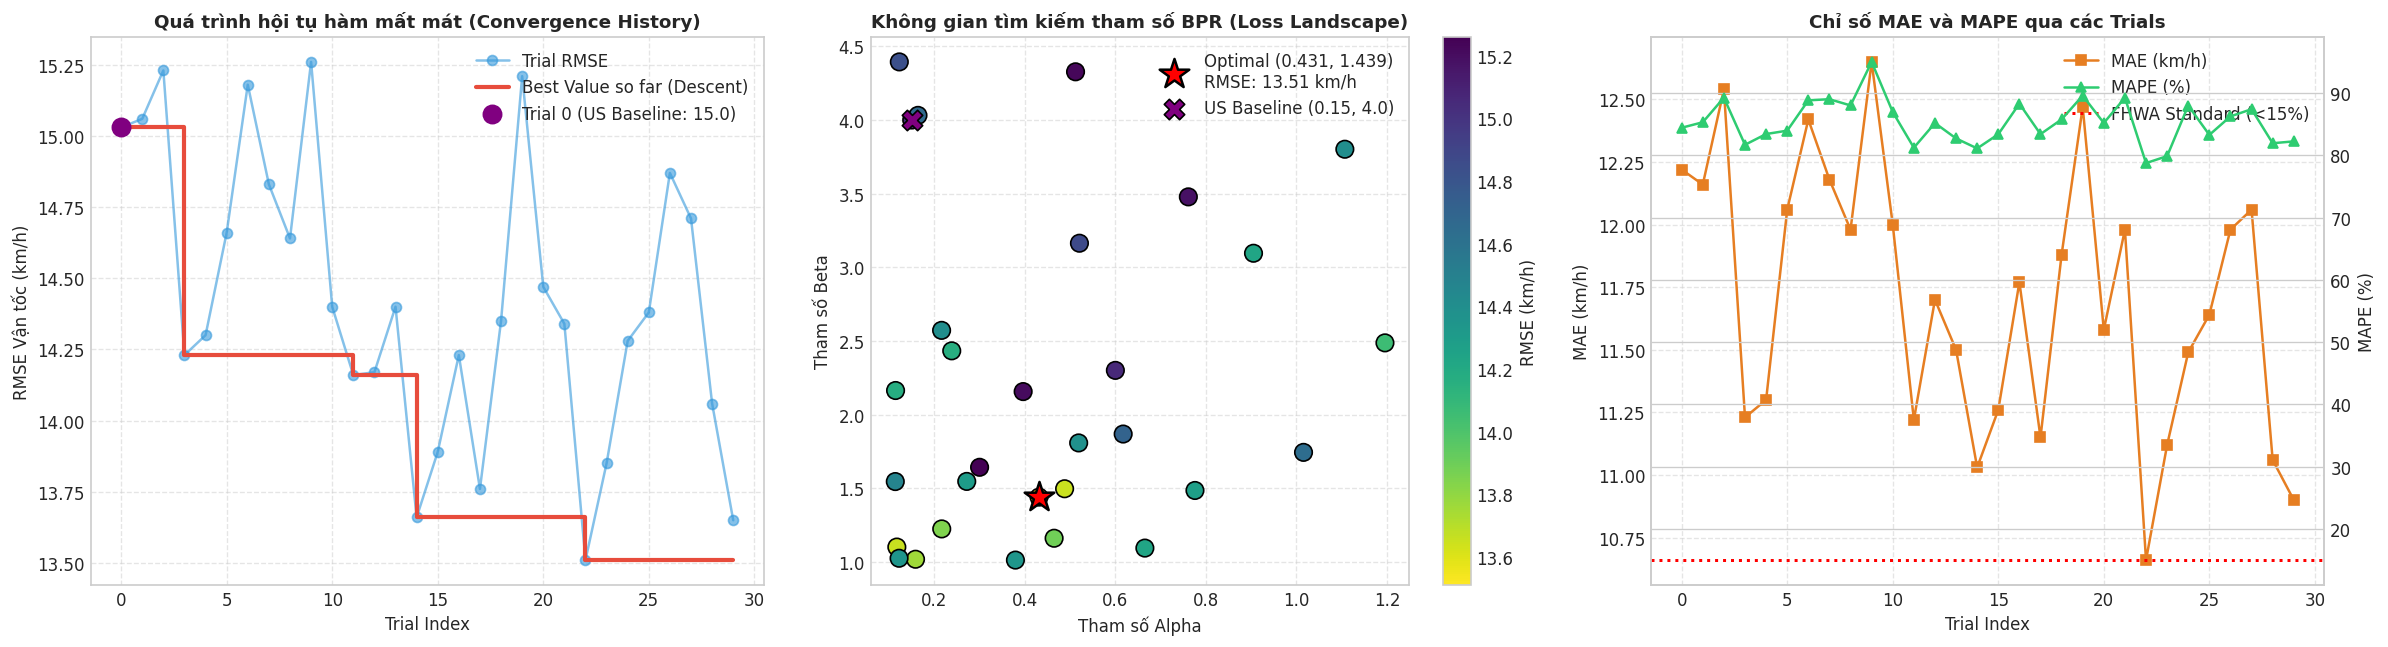

In [13]:
# ==============================================================================
# CELL 5: TRỰC QUAN HÓA QUÁ TRÌNH HỌC & KHÔNG GIAN TỐI ƯU
# Tinh chỉnh Legend nằm ở góc trên bên phải để không gây hiểu nhầm "2 ngôi sao"
# ==============================================================================

trials_df = study.trials_dataframe()
trials_df["alpha"] = trials_df["params_alpha"]
trials_df["beta"]  = trials_df["params_beta"]
trials_df["rmse"]  = trials_df["value"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

# 1. Lịch sử hội tụ (Convergence History)
best_values = [trials_df["rmse"].iloc[:i+1].min() for i in range(len(trials_df))]
axes[0].plot(trials_df["number"], trials_df["rmse"], 'o-', color='#3498db', alpha=0.6, label="Trial RMSE")
axes[0].step(trials_df["number"], best_values, where="post", color='#e74c3c', linewidth=2.5, label="Best Value so far (Descent)")
axes[0].scatter([0], [trials_df["rmse"].iloc[0]], color='purple', s=120, zorder=5, label=f"Trial 0 (US Baseline: {trials_df['rmse'].iloc[0]:.1f})")
axes[0].set_title("Quá trình hội tụ hàm mất mát (Convergence History)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Trial Index")
axes[0].set_ylabel("RMSE Vận tốc (km/h)")
axes[0].legend(loc="upper right")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Không gian tham số (Parameter Loss Landscape)
scatter = axes[1].scatter(trials_df["alpha"], trials_df["beta"], c=trials_df["rmse"], 
                          cmap="viridis_r", s=110, edgecolors="k", linewidth=1.0)
cbar = plt.colorbar(scatter, ax=axes[1])
cbar.set_label("RMSE (km/h)")

# Điểm tối ưu duy nhất (Optimal Star)
axes[1].scatter([best_alpha], [best_beta], color="red", marker="*", s=350, 
                edgecolors="black", linewidth=1.5, label=f"Optimal ({best_alpha:.3f}, {best_beta:.3f})\nRMSE: {best_rmse:.2f} km/h")
axes[1].scatter([0.15], [4.0], color="purple", marker="X", s=150, 
                edgecolors="black", label="US Baseline (0.15, 4.0)")

axes[1].set_title("Không gian tìm kiếm tham số BPR (Loss Landscape)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Tham số Alpha")
axes[1].set_ylabel("Tham số Beta")
axes[1].legend(loc="upper right", framealpha=0.9)
axes[1].grid(True, linestyle="--", alpha=0.5)

# 3. Phân bố sai số MAE & MAPE theo từng Trial
axes[2].plot(trials_df["number"], trials_df["user_attrs_mae"], 's-', color='#e67e22', label="MAE (km/h)")
ax2_twin = axes[2].twinx()
ax2_twin.plot(trials_df["number"], trials_df["user_attrs_mape"], '^-', color='#2ecc71', label="MAPE (%)")
ax2_twin.axhline(15.0, color='red', linestyle=":", linewidth=1.8, label="FHWA Standard (<15%)")
axes[2].set_title("Chỉ số MAE và MAPE qua các Trials", fontsize=11, fontweight='bold')
axes[2].set_xlabel("Trial Index")
axes[2].set_ylabel("MAE (km/h)")
ax2_twin.set_ylabel("MAPE (%)")
lines1, labels1 = axes[2].get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
axes[2].legend(lines1 + lines2, labels1 + labels2, loc="upper right")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [14]:
# ==============================================================================
# CELL 6: LƯU TRỮ MÔ HÌNH VÀ BỘ THAM SỐ HIỆU CHUẨN
# ==============================================================================

# 1. Lưu bảng lịch sử toàn bộ các trials
trials_df.to_csv(OUTPUT_HISTORY_CSV, index=False, encoding="utf-8-sig")
print(f"[*] Đã lưu lịch sử chi tiết {len(trials_df)} trials vào: {OUTPUT_HISTORY_CSV.name}")

# 2. Lưu bộ tham số tối ưu và siêu dữ liệu (Metadata) vào file JSON
model_metadata = {
    "model_name": "Calibrated_BPR_HCMC_District1",
    "calibration_method": "Bayesian_Optimization_TPE",
    "optimal_parameters": {
        "alpha": float(best_alpha),
        "beta": float(best_beta)
    },
    "training_metrics": {
        "best_rmse_kmh": float(best_rmse),
        "eval_duration_seconds": EVAL_DURATION_S,
        "step_length_seconds": STEP_LENGTH,
        "n_trials": N_TRIALS,
        "total_optimization_minutes": round(total_elapsed / 60.0, 2),
        "train_dataset": str(TRAIN_DATA_PATH.name),
        "train_time_window": f"{TRAIN_START_TIME} -> {TRAIN_END_TIME}"
    },
    "network_specification": {
        "network_file": str(NETWORK_XML_PATH.name),
        "lateral_resolution_meters": LATERAL_RESOLUTION,
        "capacity_standard": "TCVN 104:2007 (Table 10)"
    },
    "timestamp": str(pd.Timestamp.now().isoformat())
}

with open(OUTPUT_MODEL_JSON, "w", encoding="utf-8") as f:
    json.dump(model_metadata, f, indent=2, ensure_ascii=False)

print(f"[*] Đã lưu mô hình & metadata vào: {OUTPUT_MODEL_JSON.name}")
print(json.dumps(model_metadata["optimal_parameters"], indent=4))


[*] Đã lưu lịch sử chi tiết 30 trials vào: bpr_optuna_history.csv
[*] Đã lưu mô hình & metadata vào: bpr_calibrated_model.json
{
    "alpha": 0.4313287621098984,
    "beta": 1.439331757686186
}


[*] ĐANG CHẠY KIỂM ĐỊNH SO SÁNH TRÊN CÁC TẬP DỮ LIỆU ĐỘC LẬP...
[*] Validation: macro_traffic_dense_1min.csv (17:00 -> 19:00)
[*] Test OOD:   hcmc_19_10_data.csv (07:30 -> 09:30)
--> Đang đánh giá mô hình: US_BPR_Default (alpha=0.15, beta=4.0)...
[*] Dang phan tich mang luoi SUMO: C:\Users\DANH\Desktop\DS_full\.vscode\TSC_project\data\raw_data\q1_map.net.xml...
[OK] Da nap 823 edges voi 269 base OSM ways.

[*] BAT DAU CHUYEN DOI DU LIEU TOMTOM SANG SUMO EDGE COUNTS (alpha=0.15, beta=4.0)
[*] Doc duoc 14124 records tu file lich su crawl.
[*] Khoang thoi gian du lieu: 17:00:30 -> 18:58:09
[*] Thoi luong mo phong tu dong: 600 giay (~10 phut)
[*] Tong so diem do doc lap can map: 66 diem.
[*] Dang phan tich mang luoi SUMO: C:\Users\DANH\Desktop\DS_full\.vscode\TSC_project\data\raw_data\q1_map.net.xml...
[OK] Da nap 823 edges voi 269 base OSM ways.

[*] Dang thuc hien Spatial Matching va quy doi PCU:
  [OK] Phạm Ngọc Thạch (way_1157160322) -> Edge '-1157160322#2' (kc=1.58m) | PCU=1690 -> Xe 

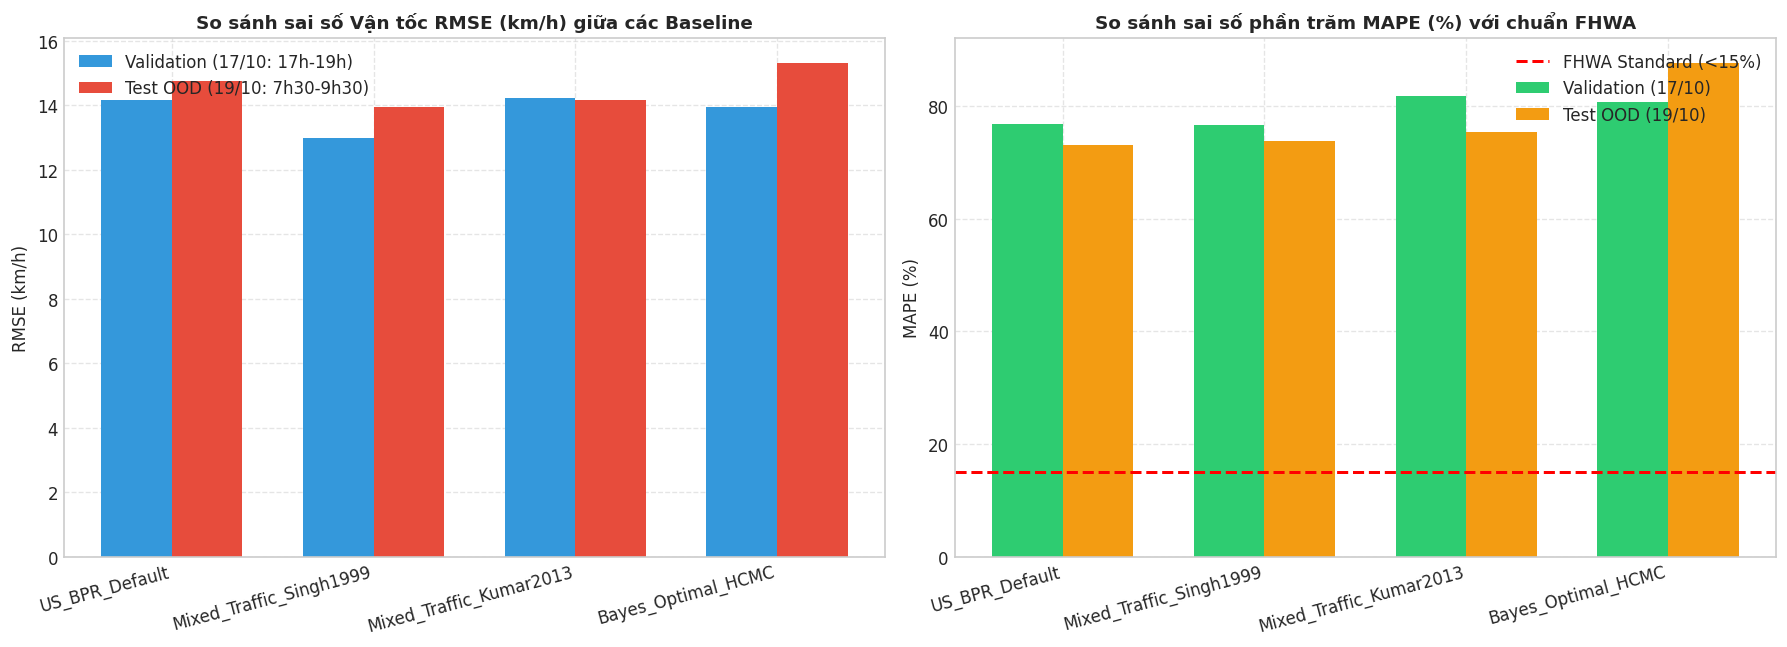

In [15]:
# ==============================================================================
# CELL 7: SO SÁNH ĐỐI CHUẨN VỚI CÁC BASELINE & PAPERS
# Chứng minh tính ĐẶC THÙ (SPECIFICITY) của bộ tham số Quận 1, TP.HCM
# Đánh giá trên cả Tập Validation (17/10: 17h-19h) và Tập Test OOD (19/10: 7h30-9h30)
# ==============================================================================

benchmark_models = {}
for name, info in BASELINES.items():
    benchmark_models[name] = {"alpha": info["alpha"], "beta": info["beta"], "desc": info["desc"]}

# Nạp mô hình tối ưu Bayes đề xuất
benchmark_models["Bayes_Optimal_HCMC"] = {
    "alpha": float(best_alpha),
    "beta": float(best_beta),
    "desc": "Mô hình đề xuất tối ưu cho Quận 1"
}

results = []

print("=" * 80)
print("[*] ĐANG CHẠY KIỂM ĐỊNH SO SÁNH TRÊN CÁC TẬP DỮ LIỆU ĐỘC LẬP...")
print(f"[*] Validation: {VALID_DATA_PATH.name} ({VALID_START_TIME} -> {VALID_END_TIME})")
print(f"[*] Test OOD:   {TEST_DATA_PATH.name} ({TEST_START_TIME} -> {TEST_END_TIME})")
print("=" * 80)

for model_name, cfg in benchmark_models.items():
    print(f"--> Đang đánh giá mô hình: {model_name} (alpha={cfg['alpha']}, beta={cfg['beta']})...")
    
    # 1. Đánh giá trên Validation Set (17/10 - Cao điểm chiều/tối)
    val_res = evaluate_bpr_params(
        alpha=cfg["alpha"],
        beta=cfg["beta"],
        dataset_path=VALID_DATA_PATH,
        start_time=VALID_START_TIME,
        end_time=VALID_END_TIME,
        eval_duration=EVAL_DURATION_S,
        step_length=STEP_LENGTH,
        trial_tag=f"val_{model_name}"
    )
    
    # 2. Đánh giá trên Test Set OOD (19/10 - Cao điểm sáng)
    test_res = evaluate_bpr_params(
        alpha=cfg["alpha"],
        beta=cfg["beta"],
        dataset_path=TEST_DATA_PATH,
        start_time=TEST_START_TIME,
        end_time=TEST_END_TIME,
        eval_duration=EVAL_DURATION_S,
        step_length=STEP_LENGTH,
        trial_tag=f"test_{model_name}"
    )
    
    results.append({
        "Model": model_name,
        "Alpha": cfg["alpha"],
        "Beta": cfg["beta"],
        "Val_RMSE": val_res["rmse"],
        "Val_MAE": val_res["mae"],
        "Val_MAPE(%)": val_res["mape"],
        "Val_GEH<5(%)": val_res["geh_rate"],
        "Test_RMSE": test_res["rmse"],
        "Test_MAE": test_res["mae"],
        "Test_MAPE(%)": test_res["mape"],
        "Test_GEH<5(%)": test_res["geh_rate"],
        "Description": cfg["desc"]
    })

comparison_df = pd.DataFrame(results)

display_cols = ["Model", "Alpha", "Beta", "Val_RMSE", "Val_MAPE(%)", "Test_RMSE", "Test_MAPE(%)", "Test_GEH<5(%)"]
print("")
print("=" * 90)
print("BẢNG SO SÁNH ĐỐI CHUẨN HIỆU QUẢ CÁC BỘ THAM SỐ BPR:")
print("=" * 90)
print(comparison_df[display_cols].to_string(index=False))

# Biểu đồ cột so sánh sai số giữa các Baseline
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5))

x = np.arange(len(comparison_df))
width = 0.35

# Biểu đồ RMSE
ax1.bar(x - width/2, comparison_df["Val_RMSE"], width, label="Validation (17/10: 17h-19h)", color="#3498db")
ax1.bar(x + width/2, comparison_df["Test_RMSE"], width, label="Test OOD (19/10: 7h30-9h30)", color="#e74c3c")
ax1.set_title("So sánh sai số Vận tốc RMSE (km/h) giữa các Baseline", fontsize=11, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(comparison_df["Model"], rotation=15, ha="right")
ax1.set_ylabel("RMSE (km/h)")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# Biểu đồ MAPE so với ngưỡng chuẩn FHWA (15%)
ax2.bar(x - width/2, comparison_df["Val_MAPE(%)"], width, label="Validation (17/10)", color="#2ecc71")
ax2.bar(x + width/2, comparison_df["Test_MAPE(%)"], width, label="Test OOD (19/10)", color="#f39c12")
ax2.axhline(15.0, color='red', linestyle="--", linewidth=1.8, label="FHWA Standard (<15%)")
ax2.set_title("So sánh sai số phần trăm MAPE (%) với chuẩn FHWA", fontsize=11, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(comparison_df["Model"], rotation=15, ha="right")
ax2.set_ylabel("MAPE (%)")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


In [16]:
# ==============================================================================
# CELL 8: QUYẾT ĐỊNH & LỰA CHỌN THAM SỐ CHO HỆ THỐNG
# Người nghiên cứu đưa ra lựa chọn cuối cùng sau khi phân tích bảng so sánh
# ==============================================================================

# Gán giá trị mặc định là kết quả tối ưu từ Bayesian Optimization
SELECTED_ALPHA = float(best_alpha)
SELECTED_BETA  = float(best_beta)

# Nếu người nghiên cứu muốn ghi đè bộ tham số theo ý định chủ quan (ví dụ chọn theo Baseline Kumar):
# SELECTED_ALPHA = 0.58
# SELECTED_BETA  = 2.04

print("=" * 70)
print("[*] XÁC NHẬN BỘ THAM SỐ CUỐI CÙNG ĐƯỢC CHỌN CHO DỰ ÁN:")
print(f"    - Alpha đã chọn: {SELECTED_ALPHA}")
print(f"    - Beta đã chọn:  {SELECTED_BETA}")
print("=" * 70)

# Cập nhật tham số này vào file bpr_best_params.json để các module downstream (MARL-TSC) nạp tự động
final_choice = {
    "selected_alpha": SELECTED_ALPHA,
    "selected_beta": SELECTED_BETA,
    "source": "Bayesian_Optimization_Study",
    "status": "APPROVED_FOR_MARL_SIMULATION",
    "updated_at": str(pd.Timestamp.now().isoformat())
}

decision_file = PROCESSED_DATA_DIR / "bpr_best_params.json"
with open(decision_file, "w", encoding="utf-8") as f:
    json.dump(final_choice, f, indent=2, ensure_ascii=False)

print(f"[OK] Đã cập nhật quyết định cấu hình vào: {decision_file.name}")


[*] XÁC NHẬN BỘ THAM SỐ CUỐI CÙNG ĐƯỢC CHỌN CHO DỰ ÁN:
    - Alpha đã chọn: 0.4313287621098984
    - Beta đã chọn:  1.439331757686186
[OK] Đã cập nhật quyết định cấu hình vào: bpr_best_params.json
